# FlipItNews — Categorising News Articles with NLP

**Business context.** FlipItNews (Gurugram) wants to make finance, business and markets easier to follow for
millennials and first-time investors through smart content discovery. Every article that enters the platform has to
be filed under the right section (**Business, Politics, Sports, Technology, Entertainment**) before it can be
recommended, searched or grouped with related stories. Doing this by hand does not scale.

**Objective.** Build a model that reads the text of an article and predicts its category, using classical NLP
(cleaning, tokenisation, stopword removal, lemmatisation, Bag of Words / TF-IDF), and create and compare several
classifiers: **Naive Bayes, Decision Tree, Nearest Neighbors and Random Forest** (plus Logistic Regression and a
Linear SVM as strong linear references).

**Plan of this notebook**

| # | Section | Rubric item |
|---|---|---|
| 1 | Libraries, configuration, loading the data | Importing & reading (10) |
| 2 | Preliminary analysis: shape, quality, articles per category, lengths, vocabulary | Exploring the dataset (10) |
| 3 | User-defined text processing: non-letters, tokens, stopwords, lemmas; one article before / after | Processing text (30) |
| 4 | Target encoding, BoW vs TF-IDF option, 75:25 train-test split | Encoding & transforming (20) |
| 5 | Naive Bayes, simple approach: confusion matrix + classification report | Model training (30) |
| 6 | Functionalised training: Decision Tree, Nearest Neighbors, Random Forest (+2 linear models) | Model training |
| 7 | BoW vs TF-IDF across all models, cross-validation, leakage check, error analysis, explainability | Beyond the rubric |
| 8 | Observations, recommendation and the questionnaire answers | Questionnaire |

## 1. Importing the libraries and loading the data

* `pandas` / `numpy` for data handling, `matplotlib` / `seaborn` / `wordcloud` for charts.
* `nltk` for tokenisation, stopwords, POS tagging and WordNet lemmatisation.
* `scikit-learn` for encoding, vectorisation, the train-test split, the classifiers and their metrics.
* `flipitnews` is this project's own package: the same vectorizer settings, model definitions and evaluation
  routine are reused by the training script, the REST API and the web app, so the notebook and production agree.

In [1]:
import os
import re
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import LabelEncoder
from wordcloud import WordCloud

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from flipitnews import preprocess as pp                                          # noqa: E402
from flipitnews.models import (SEED, VECTORIZERS, make_models, make_pipeline,     # noqa: E402
                               make_vectorizer, train_and_evaluate)

for pkg in ["stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
np.random.seed(SEED)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

PALETTE = {"Business": "#2a78d6", "Entertainment": "#e8590c", "Politics": "#7048e8",
           "Sports": "#1baf7a", "Technology": "#d6336c"}
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False})


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"nltk {nltk.__version__}")

python 3.11.0 | pandas 3.1.0 | scikit-learn 1.9.1 | nltk 3.10.4


In [2]:
df = pd.read_csv(ROOT / "data" / "flipitnews-data.csv")
df.head()

,Category,Article
0,Technology,tv future in the hands of viewers with home theatre systems plasma high-definition tvs and digital video recorders...
1,Business,worldcom boss left books alone former worldcom boss bernie ebbers who is accused of overseeing an $11bn (£5.8bn) ...
2,Sports,tigers wary of farrell gamble leicester say they will not be rushed into making a bid for andy farrell should the ...
3,Sports,yeading face newcastle in fa cup premiership side newcastle united face a trip to ryman premier league leaders yeadi...
4,Entertainment,ocean s twelve raids box office ocean s twelve the crime caper sequel starring george clooney brad pitt and julia ...


## 2. Preliminary analysis
### 2.1 Structure of the dataset

In [3]:
print("Shape of the dataset:", df.shape)
print(f"{df.shape[0]:,} news articles and {df.shape[1]} columns\n")
df.info()

Shape of the dataset: (2225, 2)
2,225 news articles and 2 columns

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Category  2225 non-null   str  
 1   Article   2225 non-null   str  
dtypes: str(2)
memory usage: 4.9 MB


In [4]:
quality = pd.DataFrame({
    "missing values": df.isna().sum(),
    "empty strings": (df.astype(str).apply(lambda s: s.str.strip() == "")).sum(),
    "unique values": df.nunique(),
})
quality

,missing values,empty strings,unique values
Category,0,0,5
Article,0,0,2126


In [5]:
dups = df[df.duplicated(keep=False)]
n_dup = df.duplicated().sum()
conflicting = df[df.Article.duplicated(keep=False)].groupby("Article").Category.nunique().gt(1).sum()
print(f"Exact duplicate rows (repeat copies): {n_dup} ({n_dup / len(df):.1%} of the data)")
print(f"Duplicated articles with conflicting labels: {conflicting}")
print("Repeat copies per category:", df[df.duplicated()].Category.value_counts().to_dict())

Exact duplicate rows (repeat copies): 99 (4.4% of the data)
Duplicated articles with conflicting labels: 0
Repeat copies per category: {'Technology': 54, 'Entertainment': 17, 'Politics': 14, 'Business': 7, 'Sports': 7}


**Data quality.** No missing values and no empty articles. There are **99 repeat copies** of articles (4.4%), all
with the same label, so they are not label noise. They are kept for the main analysis, because the brief and the
questionnaire describe the full set of 2,225 articles, but they are a leakage risk: a copy can land in the training
set while its twin lands in the test set. Section 7.3 re-runs the evaluation on the de-duplicated data to measure
exactly how much that inflates the scores.

### 2.2 News articles per category

In [6]:
counts = df.Category.value_counts()
dist = pd.DataFrame({"articles": counts, "share %": (100 * counts / len(df)).round(1)})
dist.loc["Total"] = [len(df), 100.0]
dist

,articles,share %
Category,,
Sports,511,23.0
Business,510,22.9
Politics,417,18.7
Technology,401,18.0
Entertainment,386,17.3
Total,2225,100.0


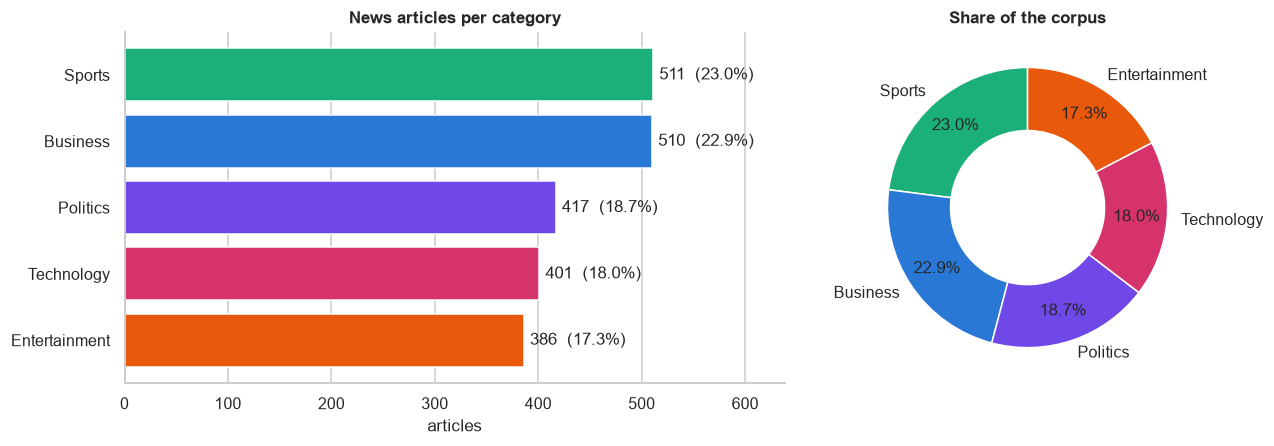

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
bars = ax[0].barh(counts.index[::-1], counts.values[::-1], color=[PALETTE[c] for c in counts.index[::-1]])
ax[0].bar_label(bars, labels=[f"{v}  ({v / len(df):.1%})" for v in counts.values[::-1]], padding=4)
ax[0].set(title="News articles per category", xlabel="articles", xlim=(0, counts.max() * 1.25))
ax[0].grid(axis="y", visible=False)
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=[PALETTE[c] for c in counts.index],
          wedgeprops={"width": 0.45, "edgecolor": "white"}, pctdistance=0.78)
ax[1].set_title("Share of the corpus")
plt.tight_layout(); savefig("01_category_distribution"); plt.show()

* **Sports (511)** is the largest category, just ahead of **Business (510)**; **Technology has only 401**
  articles and **Entertainment (386)** is the smallest.
* The largest class is only 1.3x the smallest, so the data is **mildly imbalanced at most**. Accuracy is a
  meaningful headline metric, but macro-averaged precision, recall and F1 are reported alongside it so that no
  category can hide behind the others. A stratified split keeps these proportions in train and test.

### 2.3 Article length

In [8]:
df["words"] = df.Article.str.split().str.len()
df["chars"] = df.Article.str.len()
df.groupby("Category")[["words", "chars"]].describe().loc[:, (slice(None), ["mean", "50%", "min", "max"])].round(0)

,words,chars,words,chars,words,chars,words,chars
,mean,mean,50%,50%,min,min,max,max
Category,,,,,,,,
Business,334.0,1985.0,303.0,1818.0,142.0,846.0,912.0,5406.0
Entertainment,338.0,1926.0,267.0,1557.0,144.0,823.0,3570.0,19136.0
Politics,461.0,2682.0,449.0,2626.0,90.0,501.0,4492.0,25483.0
Sports,336.0,1895.0,296.0,1640.0,116.0,719.0,1671.0,9471.0
Technology,507.0,2974.0,450.0,2636.0,165.0,973.0,3007.0,16158.0


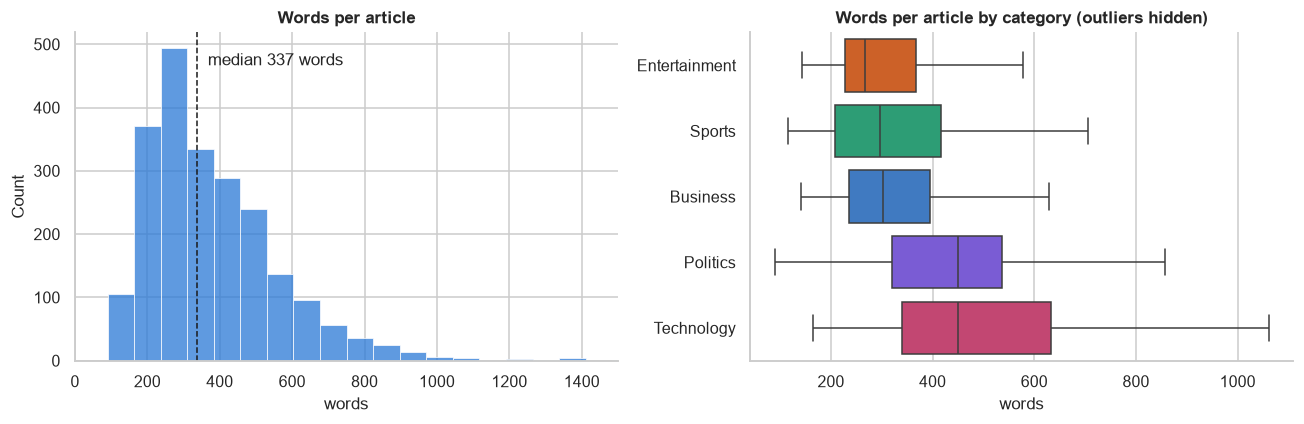

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.words, bins=60, ax=ax[0], color="#2a78d6")
ax[0].axvline(df.words.median(), color="k", ls="--", lw=1)
ax[0].text(df.words.median() + 30, ax[0].get_ylim()[1] * 0.9, f"median {df.words.median():.0f} words")
ax[0].set(title="Words per article", xlabel="words", xlim=(0, 1500))
order = df.groupby("Category").words.median().sort_values().index
sns.boxplot(data=df, y="Category", x="words", order=order, palette=PALETTE, ax=ax[1], showfliers=False)
ax[1].set(title="Words per article by category (outliers hidden)", ylabel="")
plt.tight_layout(); savefig("02_article_length"); plt.show()

* A typical article has **~340 words** (mean 390); a handful of long-form pieces reach 4,500 words, which is why the
  distribution is right-skewed.
* **Politics and Technology articles are the longest**, Sports and Entertainment the shortest. Length alone
  cannot separate the classes (the boxes overlap heavily), so the model has to rely on vocabulary. That is
  exactly what BoW / TF-IDF capture.

## 3. Processing the textual data

A raw article contains capitals, digits, punctuation, very frequent function words and many inflected forms of the
same word (*said / says / saying*). None of that helps decide the topic, and all of it inflates the vocabulary.
The user-defined function below applies four steps, each written as its own small function so it can be tested
and shown separately:

1. **Remove non-letters**: lower-case, then replace anything that is not `a-z` (digits, punctuation, `£`, `%`)
   with a space.
2. **Word-tokenise** with NLTK's `word_tokenize` (Punkt / Treebank rules).
3. **Remove stopwords** (NLTK's English list) and 1-letter fragments. One word is taken off the list: NLTK
   includes *won* (the stem of *won't*), but in news it is the past tense of *win*, and dropping it silently
   removes the key word from sentences like "Arsenal won the match".
4. **Lemmatise** with WordNet, using each word's **part of speech** from NLTK's tagger, so verbs are reduced as
   verbs (*said -> say, rising -> rise*) rather than treated as nouns, WordNet's default.

In [10]:
# NLTK lists "won" as the stem of "won't", but in news it is almost always the past tense of "win",
# one of the strongest Sports words, so it is kept.
STOP_WORDS = set(stopwords.words("english")) - {"won"}
LEMMATIZER = WordNetLemmatizer()


def remove_non_letters(text):
    """Step 1: lower-case and keep letters only."""
    return re.sub(r"[^a-z]+", " ", str(text).lower()).strip()


def tokenize_text(text):
    """Step 2: split the text into word tokens."""
    return word_tokenize(text)


def remove_stop_words(tokens):
    """Step 3: drop stopwords and 1-letter fragments."""
    return [t for t in tokens if t not in STOP_WORDS and len(t) > 1]


def to_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)


def lemmatize_tokens(tokens):
    """Step 4: POS-aware WordNet lemmatisation. Words ending in -ss / -us are kept as they are, because WordNet
    would wrongly strip their final 's' as a plural (boss -> bos, us -> u)."""
    return [t if re.search(r"(ss|us)$", t) else LEMMATIZER.lemmatize(t, to_wordnet_pos(tag))
            for t, tag in nltk.pos_tag(tokens)]


def process_text(text):
    """User-defined function: non-letters -> tokens -> stopwords -> lemmas, returned as one string."""
    tokens = tokenize_text(remove_non_letters(text))
    tokens = remove_stop_words(tokens)
    return " ".join(lemmatize_tokens(tokens))


print(f"{len(STOP_WORDS)} stopwords, e.g.:", sorted(STOP_WORDS)[:25])

197 stopwords, e.g.: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both']


### 3.1 One news article before and after processing

In [11]:
sample = df.Article[1]
stage_letters = remove_non_letters(sample)
stage_tokens = tokenize_text(stage_letters)
stage_nostop = remove_stop_words(stage_tokens)
stage_lemmas = lemmatize_tokens(stage_nostop)

print(f"Category: {df.Category[1]}\n")
print("BEFORE (raw article, first 700 characters):\n" + sample[:700] + " ...\n")
print("AFTER (processed article, first 700 characters):\n" + " ".join(stage_lemmas)[:700] + " ...")

Category: Business

BEFORE (raw article, first 700 characters):
worldcom boss  left books alone  former worldcom boss bernie ebbers  who is accused of overseeing an $11bn (£5.8bn) fraud  never made accounting decisions  a witness has told jurors.  david myers made the comments under questioning by defence lawyers who have been arguing that mr ebbers was not responsible for worldcom s problems. the phone company collapsed in 2002 and prosecutors claim that losses were hidden to protect the firm s shares. mr myers has already pleaded guilty to fraud and is assisting prosecutors.  on monday  defence lawyer reid weingarten tried to distance his client from the allegations. during cross examination  he asked mr myers if he ever knew mr ebbers  make an account ...

AFTER (processed article, first 700 characters):
worldcom boss leave book alone former worldcom boss bernie ebbers accuse oversee bn bn fraud never make accounting decision witness told juror david myers make comment question defe

In [12]:
steps = pd.DataFrame({
    "step": ["Raw article", "1. Non-letters removed", "2. Tokenised", "3. Stopwords removed", "4. Lemmatised"],
    "tokens": [len(sample.split()), len(stage_letters.split()), len(stage_tokens), len(stage_nostop),
               len(stage_lemmas)],
    "unique": [len(set(sample.split())), len(set(stage_letters.split())), len(set(stage_tokens)),
               len(set(stage_nostop)), len(set(stage_lemmas))],
    "first 12 tokens": [sample.split()[:12], stage_letters.split()[:12], stage_tokens[:12], stage_nostop[:12],
                        stage_lemmas[:12]],
})
steps

,step,tokens,unique,first 12 tokens
0,Raw article,300,182,"[worldcom, boss, left, books, alone, former, worldcom, boss, bernie, ebbers, who, is]"
1,1. Non-letters removed,296,169,"[worldcom, boss, left, books, alone, former, worldcom, boss, bernie, ebbers, who, is]"
2,2. Tokenised,296,169,"[worldcom, boss, left, books, alone, former, worldcom, boss, bernie, ebbers, who, is]"
3,3. Stopwords removed,186,125,"[worldcom, boss, left, books, alone, former, worldcom, boss, bernie, ebbers, accused, overseeing]"
4,4. Lemmatised,186,121,"[worldcom, boss, leave, book, alone, former, worldcom, boss, bernie, ebbers, accuse, oversee]"


In [13]:
changed = [(a, b) for a, b in zip(stage_nostop, stage_lemmas) if a != b]
print(f"{len(changed)} of {len(stage_nostop)} tokens changed by lemmatisation, e.g.:")
print(", ".join(f"{a} -> {b}" for a, b in list(dict.fromkeys(changed))[:20]))

54 of 186 tokens changed by lemmatisation, e.g.:
left -> leave, books -> book, accused -> accuse, overseeing -> oversee, made -> make, decisions -> decision, jurors -> juror, comments -> comment, questioning -> question, lawyers -> lawyer, arguing -> argue, problems -> problem, collapsed -> collapse, prosecutors -> prosecutor, losses -> loss, hidden -> hide, shares -> share, pleaded -> plead, assisting -> assist, allegations -> allegation


In [14]:
# Why lemmatisation rather than stemming: the same words through NLTK's Porter stemmer
stemmer = PorterStemmer()
words = ["companies", "studies", "running", "better", "said", "economy", "economic", "election", "argued", "media"]
pd.DataFrame({"word": words, "Porter stem": [stemmer.stem(w) for w in words],
              "lemma (POS-aware)": lemmatize_tokens(words)}).set_index("word").T

word,companies,studies,running,better,said,economy,economic,election,argued,media
Porter stem,compani,studi,run,better,said,economi,econom,elect,argu,media
lemma (POS-aware),company,study,run,well,say,economy,economic,election,argue,medium


* The article loses **about 40% of its tokens** (stopwords like *the, of, and, to*) while every topic-bearing
  word survives, and lemmatisation merges inflections (*shares -> share, said -> say*), so each concept is counted
  once.
* **Stemming vs lemmatisation.** The Porter stemmer chops suffixes by rule and often produces non-words
  (*compani, studi, economi*); it misses irregular forms (*said* stays *said*) and merges words with different
  meanings (*election -> elect*). The lemmatiser returns real dictionary words and, given the part of speech,
  handles irregular verbs (*said -> say*) and comparatives (*better -> well*). It is slower and not perfect
  either (WordNet reads *media* as the plural of *medium*), but the output is readable, which matters when
  the model's top words are shown to editors.

### 3.2 Processing every article

In [15]:
t0 = time.perf_counter()
df["clean"] = df.Article.map(process_text)
print(f"Processed {len(df):,} articles in {time.perf_counter() - t0:.1f} s")

# The production package (flipitnews/preprocess.py) must give the identical output, or the API would see
# differently processed text than the models were trained on.
assert df.clean.head(50).tolist() == [pp.clean_text(t) for t in df.Article.head(50)]
print("The notebook function and the production package produce identical output.")

df["clean_words"] = df.clean.str.split().str.len()
raw_vocab = len({w for t in df.Article.str.lower() for w in t.split()})
clean_vocab = len({w for t in df.clean for w in t.split()})
pd.DataFrame({"raw text": [df.words.sum(), raw_vocab, df.words.mean()],
              "processed text": [df.clean_words.sum(), clean_vocab, df.clean_words.mean()]},
             index=["total tokens", "vocabulary size", "tokens per article"]).round(0).astype(int)

Processed 2,225 articles in 33.2 s


The notebook function and the production package produce identical output.


,raw text,processed text
total tokens,868407,485038
vocabulary size,43771,23140
tokens per article,390,218


Processing removes **44% of all tokens** (390 -> 218 per article) and **nearly halves the vocabulary**
(43,771 -> 23,140 distinct words), which makes the document-term matrix smaller, faster and less noisy.

### 3.3 What each category talks about

In [16]:
top = {c: Counter(" ".join(df.clean[df.Category == c]).split()).most_common(12) for c in counts.index}
pd.DataFrame({c: [f"{w} ({n})" for w, n in v] for c, v in top.items()})

,Sports,Business,Politics,Technology,Entertainment
0,say (1123),say (1964),say (2894),say (1910),film (997)
1,win (831),year (960),mr (1699),people (961),say (953)
2,year (671),us (828),would (1054),use (931),year (684)
3,game (654),bn (785),labour (767),game (862),best (619)
4,play (593),company (628),government (745),make (627),award (533)
5,go (523),mr (602),party (726),technology (614),show (458)
6,time (485),firm (557),election (677),mobile (601),star (453)
7,first (484),market (538),people (623),one (559),music (435)
8,player (479),would (464),blair (579),phone (540),win (409)
9,take (464),rise (442),minister (569),also (537),also (398)


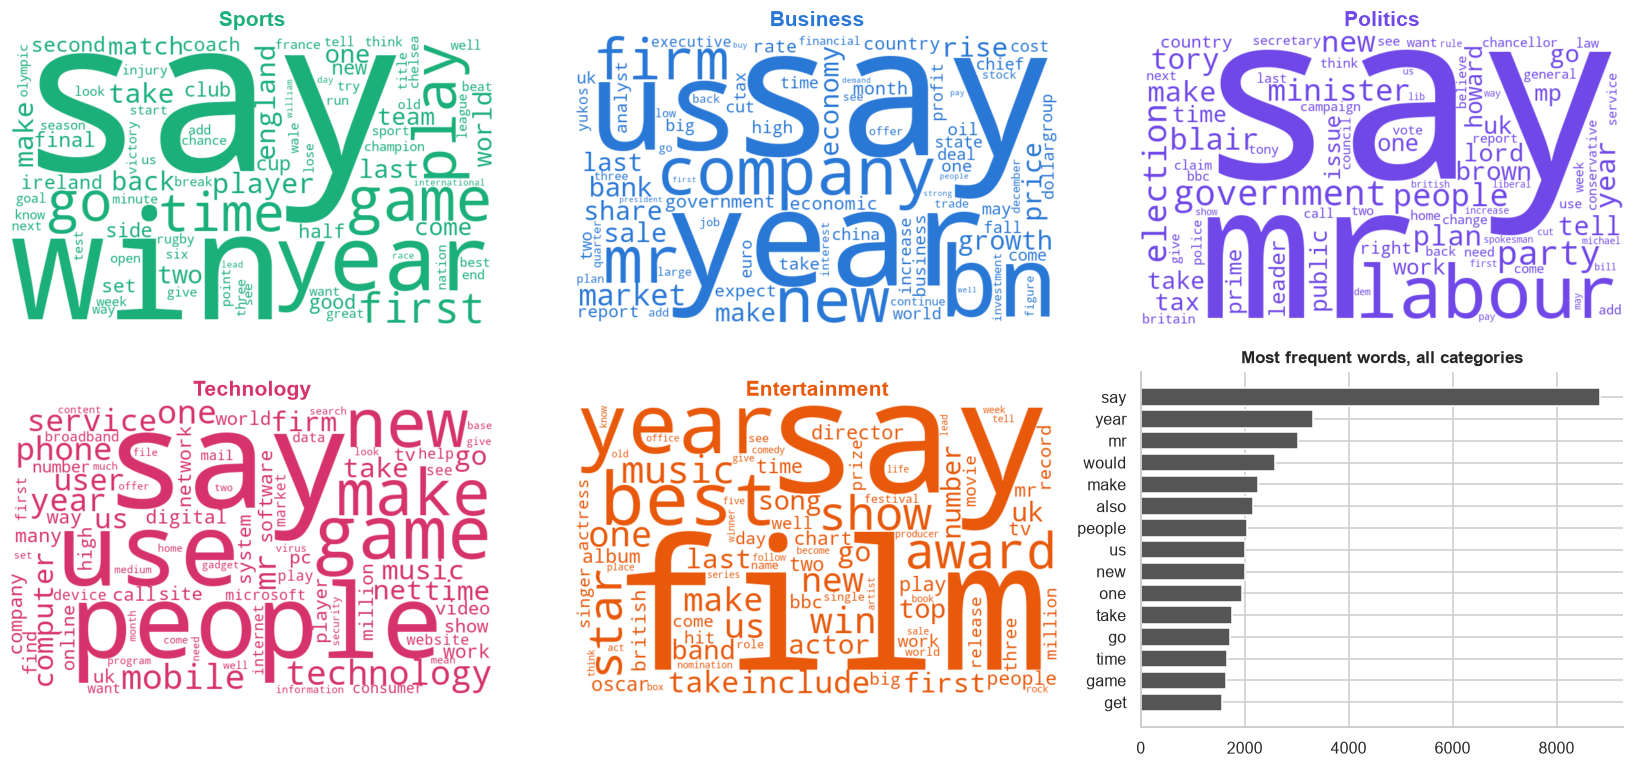

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
for ax, cat in zip(axes.flat, counts.index):
    wc = WordCloud(width=700, height=420, background_color="white", random_state=SEED, max_words=80,
                   color_func=lambda *a, c=cat, **k: PALETTE[c], collocations=False)
    ax.imshow(wc.generate(" ".join(df.clean[df.Category == cat])), interpolation="bilinear")
    ax.set_title(cat, color=PALETTE[cat], fontsize=14); ax.axis("off")
ax = axes.flat[-1]
uni = Counter(" ".join(df.clean).split())
words, n = zip(*uni.most_common(15))
ax.barh(words[::-1], n[::-1], color="#555"); ax.set_title("Most frequent words, all categories")
plt.tight_layout(); savefig("03_wordclouds"); plt.show()

* Each category has a clearly distinctive vocabulary: **Sports** (*game, win, play, player, england*),
  **Business** (*company, firm, market, bn, rise, bank*), **Politics** (*labour, government, party, election,
  blair, tory*), **Technology** (*people, use, technology, mobile, phone*), **Entertainment** (*film, best,
  award, show, star, music*).
* A few words are frequent everywhere (*say, year, new, time*). They carry little topic information, which is
  exactly what TF-IDF down-weights, while Bag of Words counts them like any other word.

## 4. Encoding and transforming the data
### 4.1 Encoding the target variable

In [18]:
encoder = LabelEncoder()
df["label"] = encoder.fit_transform(df.Category)
CLASSES = list(encoder.classes_)
pd.DataFrame({"category": CLASSES, "encoded label": encoder.transform(CLASSES),
              "articles": [counts[c] for c in CLASSES]}).set_index("category")

,encoded label,articles
category,,
Business,0,510
Entertainment,1,386
Politics,2,417
Sports,3,511
Technology,4,401


`LabelEncoder` maps the five category names to the integers 0-4 (alphabetical order). The categories have no
natural order, so this is used purely as a class index. Naive Bayes and the tree / neighbour models treat it as
a class identifier, not a magnitude, and `inverse_transform` turns predictions back into names.

### 4.2 Bag of Words vs TF-IDF: the user's choice

* **Bag of Words** (`CountVectorizer`): each article becomes a vector of raw word counts.
* **TF-IDF** (`TfidfVectorizer`): each count is re-weighted by how *rare* the word is across articles,
  `tf x log((1 + N) / (1 + df)) + 1`, then the vector is L2-normalised. Words that appear everywhere (*say,
  year*) are pushed down, and words that are specific to a few articles (*striker, tariff, broadband*) are pushed
  up. `sublinear_tf` uses `1 + log(tf)` so a word repeated 20 times does not dominate.

Both use the **same vocabulary rules** so the comparison is fair: unigrams and bigrams (*prime minister, interest
rate*), seen in at least 2 articles and at most 95% of them, keeping the 5,000 most frequent.

**The option.** Set `VECTORIZER` below (or the environment variable `FLIPIT_VECTORIZER`) to `"bow"` or `"tfidf"`;
`vectorize()` validates the choice and returns the matrices. The web app exposes the same choice as a toggle.

In [19]:
VECTORIZER = os.environ.get("FLIPIT_VECTORIZER", "tfidf")   # <- user option: "bow" or "tfidf"


def vectorize(train_text, test_text, method=VECTORIZER):
    """Fit the chosen vectorizer on the training articles only, and transform both sets."""
    if method not in VECTORIZERS:
        raise ValueError(f"method must be one of {list(VECTORIZERS)}, got {method!r}")
    vec = make_vectorizer(method)
    return vec.fit_transform(train_text), vec.transform(test_text), vec


# A small illustration of the difference on three toy sentences
toy = ["the market rose as the bank cut rates", "the team won the match", "the bank and the team agreed a deal"]
for m in ["bow", "tfidf"]:
    v = (CountVectorizer() if m == "bow" else TfidfVectorizer()).fit(toy)
    print(f"\n{VECTORIZERS[m]}:")
    print(pd.DataFrame(v.transform(toy).toarray(), columns=v.get_feature_names_out(),
                       index=["doc1", "doc2", "doc3"]).round(2).loc[:, ["the", "bank", "team", "market", "match"]])


Bag of Words:
      the  bank  team  market  match
doc1    2     1     0       1      0
doc2    2     0     1       0      1
doc3    2     1     1       0      0

TF-IDF:
       the  bank  team  market  match
doc1  0.45  0.29  0.00    0.38    0.0
doc2  0.59  0.00  0.38    0.00    0.5
doc3  0.50  0.32  0.32    0.00    0.0


In the toy example *the* gets the highest count in every Bag-of-Words row, yet it says nothing about the topic.
TF-IDF gives it the lowest weight and lifts the distinctive words (*market, match*).

### 4.3 Train-test split (75:25)

In [20]:
X, y = df.clean, df.label
X_train_text, X_test_text, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y,
                                                              random_state=SEED)
X_train, X_test, vectorizer = vectorize(X_train_text, X_test_text, VECTORIZER)

print(f"Vectorizer chosen: {VECTORIZERS[VECTORIZER]}")
print(f"Train set: X {X_train.shape}, y {y_train.shape}")
print(f"Test set : X {X_test.shape}, y {y_test.shape}")
print(f"Sparsity : {1 - X_train.nnz / np.prod(X_train.shape):.2%} of the train matrix is zero")
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}) \
    .rename(index=dict(enumerate(CLASSES))).mul(100).round(1).add_suffix(" %")

Vectorizer chosen: TF-IDF
Train set: X (1668, 5000), y (1668,)
Test set : X (557, 5000), y (557,)
Sparsity : 97.33% of the train matrix is zero


,train %,test %
label,,
Business,22.9,23.0
Entertainment,17.3,17.4
Politics,18.8,18.7
Sports,23.0,23.0
Technology,18.0,18.0


* **75:25 split: 1,668 training and 557 test articles**, each represented by 5,000 features.
* `stratify=y` keeps the category proportions identical in both sets, and `random_state=42` makes the split
  reproducible.
* The vectorizer is **fitted on the training articles only**, so the vocabulary and IDF weights never see the test
  set; fitting it on all the data first is a common, subtle form of leakage.
* More than 97% of the matrix is zero, so it is kept in sparse format.

## 5. Model training and evaluation: simple approach (Naive Bayes)

**Multinomial Naive Bayes** models each category as a distribution over words and applies Bayes' rule:
*P(category | words) ∝ P(category) · Π P(word | category)*. It assumes words are independent given the category,
which is false, but the decision it leads to is usually right for topic classification. It trains in
milliseconds and works directly with counts or TF-IDF weights. `alpha=0.1` is the Laplace smoothing that stops an
unseen word from zeroing a probability (lower than the default 1.0, chosen with cross-validation in 7.2).

In [21]:
nb = MultinomialNB(alpha=0.1)
t0 = time.perf_counter()
nb.fit(X_train, y_train)
print(f"Trained in {1000 * (time.perf_counter() - t0):.0f} ms")

y_pred_nb = nb.predict(X_test)
print(f"Train accuracy: {accuracy_score(y_train, nb.predict(X_train)):.4f}")
print(f"Test accuracy : {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Test macro F1 : {f1_score(y_test, y_pred_nb, average='macro'):.4f}\n")
print("Classification report (test set):\n")
print(classification_report(y_test, y_pred_nb, target_names=CLASSES, digits=3))

Trained in 6 ms
Train accuracy: 0.9916
Test accuracy : 0.9713
Test macro F1 : 0.9706

Classification report (test set):

               precision    recall  f1-score   support

     Business      0.960     0.945     0.953       128
Entertainment      0.969     0.959     0.964        97
     Politics      0.962     0.981     0.971       104
       Sports      1.000     1.000     1.000       128
   Technology      0.960     0.970     0.965       100

     accuracy                          0.971       557
    macro avg      0.970     0.971     0.971       557
 weighted avg      0.971     0.971     0.971       557



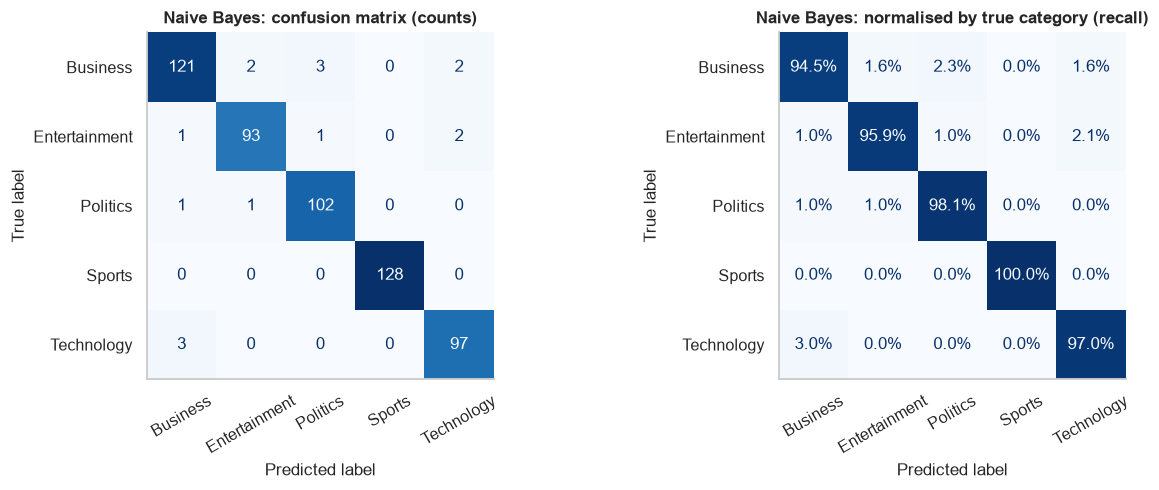

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
cm = confusion_matrix(y_test, y_pred_nb)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Naive Bayes: confusion matrix (counts)")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=CLASSES).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".1%")
ax[1].set_title("Naive Bayes: normalised by true category (recall)")
for a in ax:
    a.tick_params(axis="x", rotation=30); a.grid(False)
plt.tight_layout(); savefig("04_naive_bayes_confusion"); plt.show()

**Naive Bayes observations**

* **97.1% test accuracy and 0.971 macro F1**: 16 errors out of 557 articles, from a model that trains in
  about 5 milliseconds.
* Train accuracy is 99.2%, so the gap to test is under 2.1 points. The model is **not over-fitting**.
* **Sports is perfect** (precision and recall 1.000). Its vocabulary (*match, coach, cup, injury*) is not shared
  with any other section.
* **Business has the lowest recall (94.5%).** Its misses go to Technology, Politics and Entertainment, because
  business stories are often *about* tech firms, government policy or media companies. Business is the "hub"
  category that overlaps with all the others, and that pattern repeats in every model below.
* Precision and recall are balanced in every class (0.95 to 1.00), so the model does not favour one category
  at the expense of another.

## 6. Functionalised code: Decision Tree, Nearest Neighbors, Random Forest

`train_and_evaluate()` (in `flipitnews/models.py`) wraps the whole procedure so every model is treated identically:
it builds a scikit-learn `Pipeline` (vectorizer + model), fits it on the **training text only**, predicts the test
set, and records accuracy, macro precision / recall / F1, training time, prediction latency and the serialised
model size. A `Pipeline` also means the saved model takes raw text and can be deployed as one object.

| Model | Configuration and why |
|---|---|
| Decision Tree | Unpruned, Gini. Learns if-then rules on single words; a baseline for interpretability |
| Nearest Neighbors | k = 7, **cosine** distance, distance-weighted. Cosine is the natural similarity for text vectors; Euclidean distance on raw counts would mostly measure article length |
| Random Forest | 300 trees, each on a bootstrap sample with random feature subsets, which reduces the variance of a single tree |
| Logistic Regression, Linear SVM | Extra linear references, the standard strong baselines for sparse text features |

In [23]:
def run_all(method, models=None):
    """Train and evaluate every model with one vectorizer; return a results table and the fitted results."""
    results = {}
    for name, model in (models or make_models()).items():
        results[name] = train_and_evaluate(name, model, X_train_text, y_train, X_test_text, y_test, method)
    table = pd.DataFrame([r.row() for r in results.values()]).set_index("model")
    return table, results


def show_report(result):
    print(f"{result.name} ({VECTORIZERS[result.vectorizer]}): accuracy {result.accuracy:.4f}, "
          f"macro F1 {result.f1:.4f}")
    print(classification_report(y_test, result.y_pred, target_names=CLASSES, digits=3))


table, results = run_all(VECTORIZER)
for name in ["Decision Tree", "Nearest Neighbors", "Random Forest"]:
    show_report(results[name])

Decision Tree (TF-IDF): accuracy 0.8564, macro F1 0.8546
               precision    recall  f1-score   support

     Business      0.873     0.805     0.837       128
Entertainment      0.851     0.825     0.838        97
     Politics      0.809     0.856     0.832       104
       Sports      0.863     0.938     0.899       128
   Technology      0.885     0.850     0.867       100

     accuracy                          0.856       557
    macro avg      0.856     0.855     0.855       557
 weighted avg      0.857     0.856     0.856       557

Nearest Neighbors (TF-IDF): accuracy 0.9731, macro F1 0.9723
               precision    recall  f1-score   support

     Business      0.954     0.977     0.965       128
Entertainment      0.978     0.938     0.958        97
     Politics      0.971     0.981     0.976       104
       Sports      1.000     0.984     0.992       128
   Technology      0.961     0.980     0.970       100

     accuracy                          0.973       5

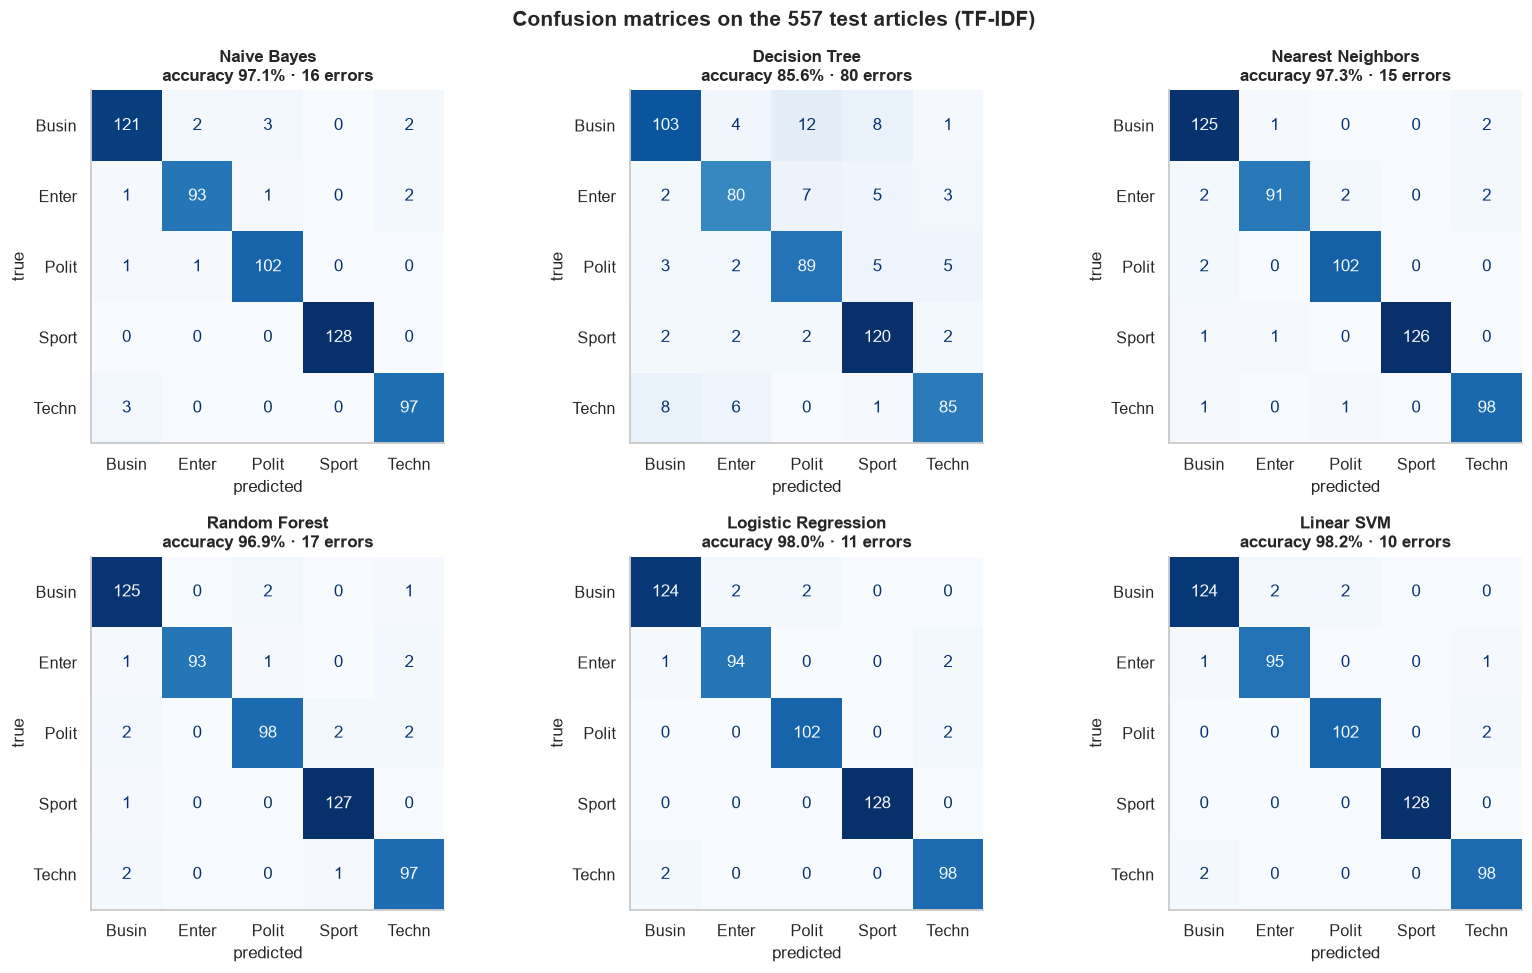

In [24]:
def plot_confusions(results, method, fname):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, (name, r) in zip(axes.flat, results.items()):
        cm = confusion_matrix(y_test, r.y_pred)
        ConfusionMatrixDisplay(cm, display_labels=[c[:5] for c in CLASSES]).plot(ax=ax, cmap="Blues",
                                                                               colorbar=False)
        ax.set_title(f"{name}\naccuracy {r.accuracy:.1%} · {cm.sum() - np.trace(cm)} errors")
        ax.grid(False); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    fig.suptitle(f"Confusion matrices on the 557 test articles ({VECTORIZERS[method]})", fontweight="bold")
    plt.tight_layout(); savefig(fname); plt.show()


plot_confusions(results, VECTORIZER, "05_confusion_matrices_tfidf")

In [25]:
summary = table.sort_values("f1_macro", ascending=False)
summary.style.format({"accuracy": "{:.4f}", "precision": "{:.4f}", "recall": "{:.4f}", "f1_macro": "{:.4f}",
                      "train_s": "{:.2f}", "predict_ms/doc": "{:.3f}", "size_kb": "{:,.0f}"}) \
    .background_gradient(subset=["accuracy", "f1_macro"], cmap="Greens")

,vectorizer,accuracy,precision,recall,f1_macro,train_s,predict_ms/doc,size_kb
model,,,,,,,,
Linear SVM,TF-IDF,0.9820,0.9814,0.9818,0.9816,1.52,0.437,380
Logistic Regression,TF-IDF,0.9803,0.9794,0.9797,0.9795,1.82,0.431,380
Nearest Neighbors,TF-IDF,0.9731,0.9730,0.9720,0.9723,1.47,0.516,"2,816"
Naive Bayes,TF-IDF,0.9713,0.9703,0.9710,0.9706,1.52,0.435,575
Random Forest,TF-IDF,0.9695,0.9705,0.9680,0.9690,3.34,0.662,"14,875"
Decision Tree,TF-IDF,0.8564,0.8564,0.8545,0.8546,2.43,0.446,213


**Observations on the four required models (TF-IDF, 557 test articles)** (`train_s` includes fitting the
vectorizer, which takes ~1.4 s of each model's time)

| Model | Test accuracy | Verdict |
|---|---|---|
| Naive Bayes | 97.1% | Excellent accuracy for almost no cost: trains in milliseconds, 0.6 MB, fully interpretable |
| Nearest Neighbors | 97.3% | Equally accurate on this split, **because cosine similarity on TF-IDF is a strong text measure**. But it has no training phase: it stores all 1,668 training vectors (2.8 MB), every prediction compares against all of them, and it drops to 94.3% with Bag of Words |
| Random Forest | 97.0% | Strong and robust, but the largest (~15 MB) and slowest model, and it does not beat Naive Bayes. Averaging 300 trees fixes most of the single tree's variance |
| Decision Tree | 85.6% | Clearly the weakest. A single tree fits the training data perfectly by splitting on individual words, so it memorises rather than generalises; its errors are spread across every class |

The two linear references, **Logistic Regression (98.0%) and the Linear SVM (98.2%)**, are the most accurate.
With 5,000 sparse features and only 1,668 articles, the classes are almost linearly separable, and a linear model
with regularisation is the right bias for that shape of data. On a single split of 557 articles, each error is
0.18 points, so differences under 1 point are only a few articles. Section 7.2 checks the ranking with
cross-validation before any conclusion is drawn.

## 7. Going further
### 7.1 Bag of Words vs TF-IDF for every model

In [26]:
other = "bow" if VECTORIZER == "tfidf" else "tfidf"
table_other, results_other = run_all(other)
both = pd.concat([table, table_other]).reset_index()
pivot = both.pivot(index="model", columns="vectorizer", values="accuracy")
pivot["TF-IDF - BoW (pts)"] = 100 * (pivot["TF-IDF"] - pivot["Bag of Words"])
pivot.sort_values("TF-IDF", ascending=False).round(4)

vectorizer,Bag of Words,TF-IDF,TF-IDF - BoW (pts)
model,,,
Linear SVM,0.9695,0.9820,1.2567
Logistic Regression,0.9695,0.9803,1.0772
Nearest Neighbors,0.9425,0.9731,3.0521
Naive Bayes,0.9767,0.9713,-0.5386
Random Forest,0.9695,0.9695,0.0000
Decision Tree,0.8384,0.8564,1.7953


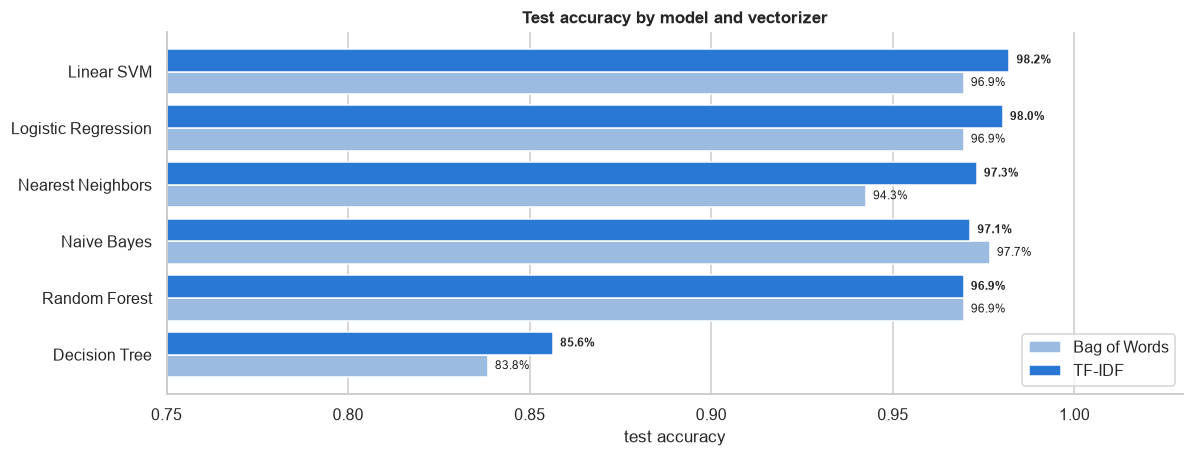

In [27]:
fig, ax = plt.subplots(figsize=(11, 4.3))
order = pivot.sort_values("TF-IDF").index
yy = np.arange(len(order))
ax.barh(yy - 0.2, pivot.loc[order, "Bag of Words"], 0.4, label="Bag of Words", color="#9bbbe0")
ax.barh(yy + 0.2, pivot.loc[order, "TF-IDF"], 0.4, label="TF-IDF", color="#2a78d6")
for i, m in enumerate(order):
    ax.text(pivot.loc[m, "Bag of Words"] + 0.002, i - 0.2, f"{pivot.loc[m, 'Bag of Words']:.1%}", va="center",
            fontsize=8)
    ax.text(pivot.loc[m, "TF-IDF"] + 0.002, i + 0.2, f"{pivot.loc[m, 'TF-IDF']:.1%}", va="center", fontsize=8,
            fontweight="bold")
ax.set_yticks(yy, order); ax.set_xlim(0.75, 1.03); ax.set_xlabel("test accuracy")
ax.set_title("Test accuracy by model and vectorizer"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("06_bow_vs_tfidf"); plt.show()

* **TF-IDF clearly helps the similarity- and weight-based models**: Nearest Neighbors **+3.1 points**, Linear
  SVM +1.3, Logistic Regression +1.1, Decision Tree +1.8. With raw counts, the distance between two articles is
  dominated by frequent, uninformative words (*say, year*). TF-IDF down-weights them and normalises for length.
* **Random Forest is indifferent** (97.0% with both): a tree splits one feature at a time, so re-scaling a column
  barely changes it. **Naive Bayes is slightly better with Bag of Words on this split** (-0.5 points, 3
  articles), since Multinomial Naive Bayes is derived for word *counts*. Cross-validation (next section) reverses
  that difference (TF-IDF 97.2% vs BoW 96.8%), so it is noise.
* Overall **TF-IDF is the more effective representation**: the three best cross-validated configurations all use
  it, at exactly the same matrix size and cost as Bag of Words.

### 7.2 Is the ranking stable? 5-fold cross-validation

One split of 557 articles can be lucky or unlucky: each test error is worth 0.18 accuracy points. Stratified 5-fold
cross-validation on the **training set** (the test set stays untouched) gives every model five scores, so we can
see both the mean and the spread.

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for method in ["bow", "tfidf"]:
    for name, model in make_models().items():
        s = cross_validate(make_pipeline(model, method), X_train_text, y_train, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro"])
        cv_rows.append({"model": name, "vectorizer": VECTORIZERS[method],
                        "cv accuracy": s["test_accuracy"].mean(), "± std": s["test_accuracy"].std(),
                        "cv macro F1": s["test_f1_macro"].mean(), "min fold": s["test_accuracy"].min()})
cv_table = pd.DataFrame(cv_rows).sort_values("cv accuracy", ascending=False).reset_index(drop=True)
cv_table.round(4)

,model,vectorizer,cv accuracy,± std,cv macro F1,min fold
0,Logistic Regression,TF-IDF,0.9778,0.0052,0.9774,0.9701
1,Linear SVM,TF-IDF,0.9772,0.0045,0.9769,0.9731
2,Naive Bayes,TF-IDF,0.9718,0.0049,0.9711,0.9640
3,Naive Bayes,Bag of Words,0.9682,0.0041,0.9675,0.9640
4,Logistic Regression,Bag of Words,0.9628,0.0084,0.9622,0.9491
5,Nearest Neighbors,TF-IDF,0.9628,0.0031,0.9619,0.9581
6,Random Forest,Bag of Words,0.9610,0.0095,0.9603,0.9431
7,Random Forest,TF-IDF,0.9586,0.0088,0.9579,0.9461
8,Linear SVM,Bag of Words,0.9574,0.0083,0.9567,0.9431
9,Nearest Neighbors,Bag of Words,0.9431,0.0098,0.9415,0.9339


In [29]:
alphas = [0.01, 0.03, 0.1, 0.3, 1.0]
alpha_rows = []
for method in ["bow", "tfidf"]:
    for a in alphas:
        s = cross_validate(make_pipeline(MultinomialNB(alpha=a), method), X_train_text, y_train, cv=cv, n_jobs=-1)
        alpha_rows.append({"vectorizer": VECTORIZERS[method], "alpha": a, "cv accuracy": s["test_score"].mean()})
pd.DataFrame(alpha_rows).pivot(index="alpha", columns="vectorizer", values="cv accuracy").round(4)

vectorizer,Bag of Words,TF-IDF
alpha,,
0.01,0.9682,0.9712
0.03,0.9682,0.9718
0.10,0.9682,0.9718
0.30,0.9688,0.9706
1.00,0.9700,0.9682


* Cross-validation **confirms the ranking**: Logistic Regression and Linear SVM with TF-IDF (97.7-97.8%) >
  Naive Bayes (97.2%) > Nearest Neighbors (96.3%) > Random Forest (95.9-96.1%) >> Decision Tree (80.6-83.0%).
* The top three are within 0.6 points of each other, about one standard deviation (0.45-0.5 points), so they are
  effectively tied. The Decision Tree is clearly worse and has the largest fold-to-fold spread (up to ±1.5).
* The single test split was **optimistic for the Decision Tree** (85.6% on the test set vs 80.6% in
  cross-validation), a good example of why a single split should not be used to choose a model.
* **Naive Bayes smoothing:** `alpha` from 0.03 to 0.1 is best with TF-IDF; the scikit-learn default of 1.0 is
  0.4 points worse because it over-smooths rare but informative words. Bag of Words is insensitive to it. This
  justifies `alpha=0.1`.

### 7.3 Leakage check: removing the 99 duplicate articles

If an article and its copy are split across train and test, the model is partly tested on text it has already
seen. Re-running the full comparison on the **2,126 unique articles** (same 75:25 stratified split) measures how
much the duplicates inflate the scores.

In [30]:
dedup = df.drop_duplicates(subset="Article").reset_index(drop=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(dedup.clean, dedup.label, test_size=0.25, stratify=dedup.label,
                                              random_state=SEED)
leak_in_test = X_test_text.isin(set(X_train_text)).sum()
print(f"Original split: {leak_in_test} of {len(X_test_text)} test articles also appear in the training set")
print(f"De-duplicated : {len(dedup):,} articles -> train {len(Xd_tr)}, test {len(Xd_te)}, overlap "
      f"{Xd_te.isin(set(Xd_tr)).sum()}")
dd_rows = []
for name, model in make_models().items():
    r = train_and_evaluate(name, model, Xd_tr, yd_tr, Xd_te, yd_te, "tfidf")
    dd_rows.append({"model": name, "accuracy (all 2,225)": table.loc[name, "accuracy"] if VECTORIZER == "tfidf"
                    else table_other.loc[name, "accuracy"], "accuracy (unique 2,126)": r.accuracy})
dd = pd.DataFrame(dd_rows).set_index("model")
dd["change (pts)"] = 100 * (dd["accuracy (unique 2,126)"] - dd["accuracy (all 2,225)"])
dd.round(4)

Original split: 42 of 557 test articles also appear in the training set
De-duplicated : 2,126 articles -> train 1594, test 532, overlap 4


,"accuracy (all 2,225)","accuracy (unique 2,126)",change (pts)
model,,,
Naive Bayes,0.9713,0.9737,0.2410
Decision Tree,0.8564,0.8365,-1.9907
Nearest Neighbors,0.9731,0.9680,-0.5025
Random Forest,0.9695,0.9586,-1.0833
Logistic Regression,0.9803,0.9812,0.0952
Linear SVM,0.9820,0.9831,0.1036


* In the original split, **42 of the 557 test articles (7.5%) have an exact copy in the training set.**
* Removing the duplicates **does not hurt the best models at all**: Naive Bayes +0.2, Logistic Regression +0.1,
  Linear SVM +0.1. **The headline results are genuine, not the product of memorised copies.**
* The models that memorise lose ground: **Decision Tree -2.0, Random Forest -1.1, Nearest Neighbors -0.5**.
  Trees can learn an exact copy's rare words, and a duplicate's nearest neighbour is its own copy at distance
  zero, so these models were partly flattered by the duplicates.
* In production, FlipItNews should de-duplicate articles (for example by hashing the cleaned text) before
  retraining.

### 7.4 Error analysis: which articles does the best model get wrong?

In [31]:
best_name = cv_table.iloc[0]["model"]
best_method = {v: k for k, v in VECTORIZERS.items()}[cv_table.iloc[0]["vectorizer"]]
best = (results if best_method == VECTORIZER else results_other)[best_name]
print(f"Best model by cross-validated accuracy: {best_name} + {VECTORIZERS[best_method]} "
      f"(test accuracy {best.accuracy:.4f}, {int((best.y_pred != y_test.values).sum())} errors)\n")
proba_model = best.pipeline
wrong = pd.DataFrame({"true": encoder.inverse_transform(y_test), "predicted": encoder.inverse_transform(best.y_pred),
                      "article (first 160 characters)": df.Article.loc[X_test_text.index].str[:160].values},
                     index=X_test_text.index)
wrong = wrong[wrong.true != wrong.predicted]
wrong

Best model by cross-validated accuracy: Logistic Regression + TF-IDF (test accuracy 0.9803, 11 errors)



,true,predicted,article (first 160 characters)
1207,Entertainment,Business,uk s national gallery in the pink the national gallery home to some of the uk s greatest artworks has seen a big j...
230,Entertainment,Technology,tv show unites angolan families angolan families who are attempting to track each other down after being separated ...
1933,Entertainment,Technology,fears raised over ballet future fewer children in the uk are following in the dainty footsteps of dancers like darce...
1144,Business,Entertainment,mcdonald s to sponsor mtv show mcdonald s the world s largest restaurant chain is to sponsor a programme on music ...
535,Technology,Business,pc ownership to double by 2010 the number of personal computers worldwide is expected to double by 2010 to 1.3 bil...
1532,Business,Politics,saudi ministry to employ women women will be employed in saudi arabia s foreign ministry for the first time this yea...
592,Technology,Business,china ripe for media explosion asia is set to drive global media growth to 2008 and beyond with china and india f...
1702,Business,Politics,call to overhaul uk state pension the uk pension system has been branded inadequate and too complex by a leading ret...
1669,Politics,Technology,mps issued with blackberry threat mps will be thrown out of the commons if they use blackberries in the chamber spea...
310,Politics,Technology,mps issued with blackberry threat mps will be thrown out of the commons if they use blackberries in the chamber spea...


* The best model makes only **11 errors out of 557**, and almost all of them are **genuinely cross-topic
  stories** that a human editor could also file in two sections: the National Gallery's visitor numbers, McDonald's
  sponsoring an MTV show, PC-ownership forecasts, a UK state-pension overhaul, a Saudi ministry hiring women, and
  MPs being banned from using BlackBerry phones in the Commons (politics about a gadget). That last article
  appears **twice**: it is one of the duplicates.
* **Sports has no errors.** **Business is involved in 7 of the 11 errors**, as the true or the predicted
  category, which confirms it as the hub topic. Two Entertainment stories about a TV show and the future of
  ballet were read as Technology.
* Product implication: such articles really belong to two sections. FlipItNews should show the top-2 categories
  (or treat it as multi-label tagging) when the model is unsure. The next section measures how well "unsure" can be
  detected.

### 7.5 Confidence: when should a human editor check?

Logistic Regression returns a probability for each category. If articles whose top probability is below a
threshold go to an editor, how many can be filed automatically, and how accurate are those?

In [32]:
proba = proba_model.predict_proba(X_test_text) if hasattr(proba_model, "predict_proba") else \
    (results if VECTORIZER == "tfidf" else results_other)["Logistic Regression"].pipeline.predict_proba(X_test_text)
conf, pred_c = proba.max(axis=1), proba.argmax(axis=1)
rows = []
for th in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8]:
    auto = conf >= th
    rows.append({"confidence threshold": th, "auto-filed %": 100 * auto.mean(),
                 "accuracy on auto-filed %": 100 * (pred_c[auto] == y_test.values[auto]).mean(),
                 "sent to editor": int((~auto).sum()),
                 "errors caught": int(((pred_c != y_test.values) & ~auto).sum()),
                 "errors missed": int(((pred_c != y_test.values) & auto).sum())})
conf_table = pd.DataFrame(rows).set_index("confidence threshold")
conf_table.round(1)

,auto-filed %,accuracy on auto-filed %,sent to editor,errors caught,errors missed
confidence threshold,,,,,
0.0,100.0,98.0,0,0,11
0.4,98.9,98.5,6,3,8
0.5,97.1,99.6,16,9,2
0.6,95.5,99.8,25,10,1
0.7,92.1,99.8,44,10,1
0.8,86.5,100.0,75,11,0


* The model's confidence is **well aligned with correctness**. At a **0.6 threshold**, 95.5% of articles are filed
  automatically at **99.8% accuracy**, and only 25 articles (4.5%) go to an editor. Those 25 contain **10 of the
  11 errors**.
* That turns a 98%-accurate model into a near-error-free workflow at the cost of reviewing about 1 article in 20.
  The web app uses the same 0.6 rule to flag "send to an editor".

### 7.6 Explainability: the words that drive each category

Naive Bayes is fully transparent. For every category, the words with the highest log-probability *ratio* against
the other categories are the ones that push an article into it.

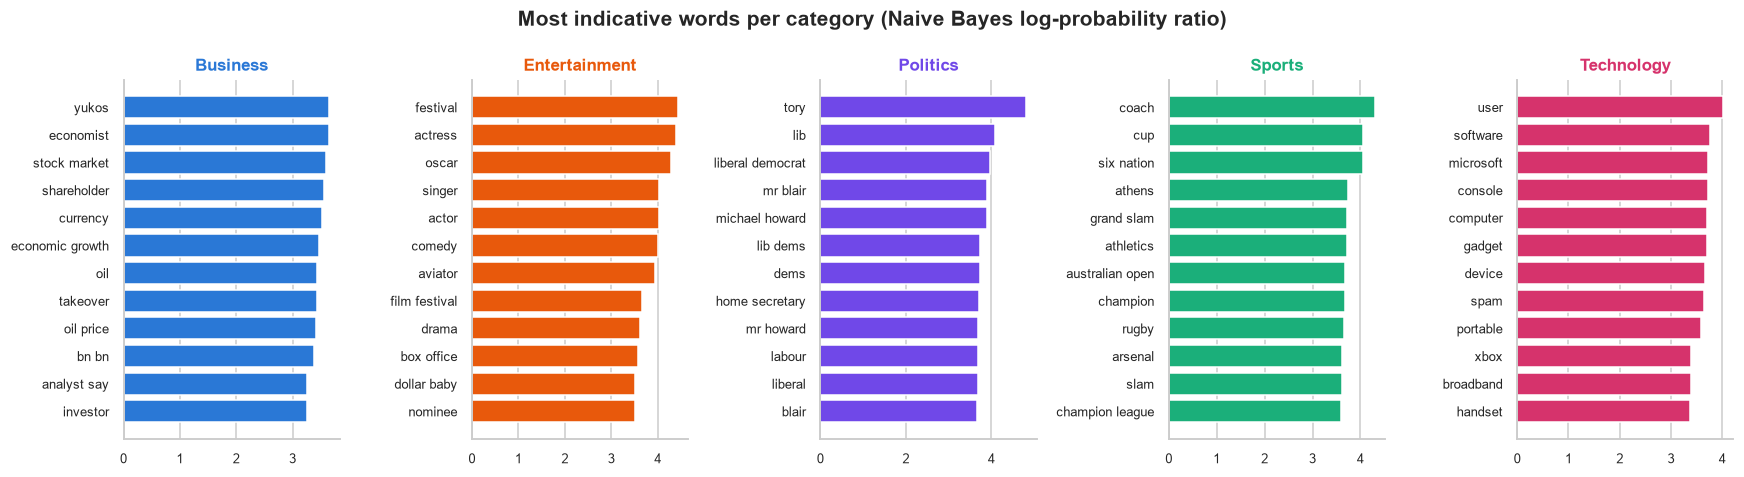

In [33]:
nb_pipe = (results if VECTORIZER == "tfidf" else results_other)["Naive Bayes"].pipeline
vocab = nb_pipe.named_steps["vectorizer"].get_feature_names_out()
logp = nb_pipe.named_steps["model"].feature_log_prob_
fig, axes = plt.subplots(1, 5, figsize=(16, 4.4))
for i, (ax, cat) in enumerate(zip(axes, CLASSES)):
    ratio = logp[i] - np.log(np.exp(np.delete(logp, i, axis=0)).mean(axis=0))
    idx = np.argsort(ratio)[-12:]
    ax.barh(vocab[idx], ratio[idx], color=PALETTE[cat])
    ax.set_title(cat, color=PALETTE[cat]); ax.tick_params(labelsize=8.5); ax.grid(axis="y", visible=False)
fig.suptitle("Most indicative words per category (Naive Bayes log-probability ratio)", fontweight="bold")
plt.tight_layout(); savefig("07_indicative_words"); plt.show()

* The model has learned the vocabulary a human editor would use: *coach, cup, champion, rugby* for Sports;
  *economist, shareholder, currency, investor* for Business; *tory, labour, liberal democrat, home secretary* for
  Politics; *user, software, computer, device, broadband* for Technology; *festival, actress, oscar, box office*
  for Entertainment.
* **Bigrams pay off**: *stock market, economic growth, oil price, grand slam, box office, home secretary* are
  among the strongest features.
* There is also a warning sign. Some top features are **names tied to 2004-05 British news**: *Yukos* (a Russian
  oil company in the news at the time), *Mr Blair, Michael Howard, Arsenal, Xbox*. They are correct for this corpus
  but will not generalise to today's Indian finance news. This is the main reason to retrain on FlipItNews's own
  articles (section 8.3).

### 7.7 Predicting new, unseen articles

In [34]:
new_articles = [
    "The Reserve Bank kept the repo rate unchanged as inflation eased and quarterly profits at major lenders rose.",
    "India clinched the series after a brilliant century from the captain in the final one-day match at Mumbai.",
    "The new smartphone ships with a faster chip, better camera software and a battery that lasts two days.",
    "The opposition party walked out of parliament after the minister refused to answer questions on the bill.",
    "The director's latest film won best picture at the awards ceremony, and its lead actress took the top prize.",
]
final_pipe = best.pipeline
pred = encoder.inverse_transform(final_pipe.predict([pp.clean_text(t) for t in new_articles]))
pd.DataFrame({"article": [t[:95] + "..." for t in new_articles], "predicted category": pred})

,article,predicted category
0,The Reserve Bank kept the repo rate unchanged as inflation eased and quarterly profits at major...,Business
1,India clinched the series after a brilliant century from the captain in the final one-day match...,Sports
2,"The new smartphone ships with a faster chip, better camera software and a battery that lasts tw...",Technology
3,The opposition party walked out of parliament after the minister refused to answer questions on...,Politics
4,"The director's latest film won best picture at the awards ceremony, and its lead actress took t...",Entertainment


## 8. Observations, recommendation and answers
### 8.1 Final comparison

In [35]:
final = cv_table.merge(both[["model", "vectorizer", "accuracy", "f1_macro", "train_s", "predict_ms/doc", "size_kb"]],
                       on=["model", "vectorizer"]).rename(columns={"accuracy": "test accuracy",
                                                                    "f1_macro": "test macro F1"})
final = final[["model", "vectorizer", "cv accuracy", "± std", "test accuracy", "test macro F1", "train_s",
               "predict_ms/doc", "size_kb"]]
final.round(4)

,model,vectorizer,cv accuracy,± std,test accuracy,test macro F1,train_s,predict_ms/doc,size_kb
0,Logistic Regression,TF-IDF,0.9778,0.0052,0.9803,0.9795,1.8152,0.4307,379.6328
1,Linear SVM,TF-IDF,0.9772,0.0045,0.9820,0.9816,1.5219,0.4374,379.5352
2,Naive Bayes,TF-IDF,0.9718,0.0049,0.9713,0.9706,1.5220,0.4350,574.8730
3,Naive Bayes,Bag of Words,0.9682,0.0041,0.9767,0.9761,1.4528,0.4375,535.7119
4,Logistic Regression,Bag of Words,0.9628,0.0084,0.9695,0.9678,1.5905,0.4538,340.4570
5,Nearest Neighbors,TF-IDF,0.9628,0.0031,0.9731,0.9723,1.4654,0.5159,2816.1426
6,Random Forest,Bag of Words,0.9610,0.0095,0.9695,0.9692,3.3969,0.6595,16377.3369
7,Random Forest,TF-IDF,0.9586,0.0088,0.9695,0.9690,3.3389,0.6623,14874.8398
8,Linear SVM,Bag of Words,0.9574,0.0083,0.9695,0.9688,2.0277,0.4226,340.3545
9,Nearest Neighbors,Bag of Words,0.9431,0.0098,0.9425,0.9409,1.4703,0.5267,2776.9307


### 8.2 Observations and comments on the models

1. **Every model except the Decision Tree is above 94%**, because the five categories have very distinctive
   vocabularies (section 3.3). The real differences show up in stability, cost and behaviour on ambiguous articles.
2. **Naive Bayes is the best of the four required models.** It is the most accurate in cross-validation (97.2%
   with TF-IDF, 96.8% with BoW), it was the strongest on the test split (97.7% with BoW, 97.1% with TF-IDF), it
   trains in milliseconds and its decisions can be read word by word. It is the ideal baseline and a strong
   fallback model.
3. **Nearest Neighbors** matches Naive Bayes on this test split with TF-IDF (97.3%) but is 0.9 points lower in
   cross-validation. It depends strongly on the representation (94.3% with BoW), and its memory and prediction
   cost grow with every article added to the archive.
4. **Random Forest** (97.0% on test, 95.9-96.1% in CV) is robust but the heaviest model (~15 MB, the slowest to
   train and predict), it loses 1.1 points without duplicates, and it gives no benefit over Naive Bayes on
   sparse text.
5. **The Decision Tree** (80.6-83.0% in CV) over-fits: a single tree memorises individual words, has the largest
   fold-to-fold variance, and loses the most when duplicates are removed. It is not suitable on its own.
6. **TF-IDF beats Bag of Words** for the distance-based and linear models and ties for Naive Bayes and Random
   Forest. It is the better default.
7. **Linear models are best overall.** Logistic Regression and the Linear SVM with TF-IDF reach 97.7-97.8% in
   cross-validation and 98.0-98.2% on the test set, with 11 or fewer errors, all on genuinely cross-topic
   stories.

### 8.3 Recommendation for FlipItNews

* **Deploy Logistic Regression + TF-IDF**: the highest cross-validated accuracy (97.8%), 98.0% on unseen
  articles, **calibrated probabilities** (which the Linear SVM lacks) for the editor-review rule, a 0.4 MB model
  and under 1 ms per article. It is exposed through a REST API and a web app in this repository, with Naive Bayes
  available as a lightweight alternative.
* **Route articles with confidence below 0.6 to an editor**: about 5% of articles, which contain 10 of 11 errors.
* **Show the top two categories** for cross-topic stories (business + technology, business + politics), or move
  to multi-label tagging.
* **Retrain on FlipItNews's own articles.** This corpus is British news from the mid-2000s (*blair, tory,
  labour*); Indian markets coverage (*sensex, rbi, sebi*) has different vocabulary. Monitor the share of
  low-confidence articles as an early drift alarm, de-duplicate before retraining, and consider adding finance
  sub-categories (markets, personal finance, startups) that match the product.
* A transformer (e.g. DistilBERT) could recover a few of the remaining errors, but at roughly 100x the inference
  cost. At 98% accuracy with a review rule, that is not justified yet.

## 9. Questionnaire

| # | Question | Answer |
|---|---|---|
| 1 | How many news articles are present in the dataset? | **2,225** articles (2,126 unique; 99 are repeat copies) |
| 2 | Most of the news articles are from ___ category. | **Sports**, 511 articles (23.0%), just ahead of Business with 510 |
| 3 | Only ___ no. of articles belong to the 'Technology' category. | **401** (18.0%) |
| 4 | What are stopwords and why remove them? | See below |
| 5 | Difference between stemming and lemmatisation? | See below |
| 6 | Which is more efficient, Bag of Words or TF-IDF? | **TF-IDF** (see below) |
| 7 | Shape of train and test sets after a 75:25 split? | **Train: X (1668, 5000), y (1668,); Test: X (557, 5000), y (557,)**. 5,000 is the chosen vocabulary size; with an unrestricted unigram vocabulary the column count is the number of distinct training words |
| 8 | Best performing model: (a) Random Forest (b) Nearest Neighbors (c) Naive Bayes | **(c) Naive Bayes**: 97.2% CV accuracy vs 96.3% for Nearest Neighbors and 96.1% for Random Forest, the best test accuracy (97.7% with BoW), and by far the fastest and smallest |
| 9 | Precision and recall are equally important for this use case (T/F) | **True** |

**Q4. Stopwords** are the most frequent function words of a language: articles, pronouns, prepositions,
conjunctions and auxiliary verbs (*the, is, of, and, to, he, which*). They are needed for grammar but carry almost
no information about the topic, since they occur in every category at similar rates. Removing them (1) **reduces
noise**, so the model's weight goes to content words like *election* or *striker*; (2) **shrinks the data**: here
the article lost ~40% of its tokens, which makes the document-term matrix smaller and training faster; and (3)
**improves similarity measures**, because two articles are no longer "similar" just because both use *the* a lot.
This matters most for Bag of Words, which has no other way of ignoring frequent words. Caveat: for tasks where
function words matter (sentiment with *not*, authorship, question answering) stopwords should be kept or the
list customised.

**Q5. Stemming vs lemmatisation.** Both reduce inflected words to a common base so that *rise, rises, rising*
count as one feature.

| | Stemming (e.g. Porter) | Lemmatisation (e.g. WordNet) |
|---|---|---|
| How | Chops suffixes with fixed rules | Looks the word up in a dictionary, using its part of speech |
| Output | A stem, often not a real word: *studies -> studi, economy -> economi* | A real dictionary word (lemma): *studies -> study* |
| Irregular forms | Missed: *said -> said, better -> better* | Handled: *said -> say, better -> well* |
| Over-merging | *election, elected, elect* -> *elect* (different meanings merged) | Keeps *election* (noun) and *elect* (verb) apart |
| Speed | Very fast, no resources needed | Slower; needs WordNet and ideally a POS tagger |

Lemmatisation was used here because its output is readable (the model's top words are shown to users) and more
accurate; the extra cost (~35 s for 2,225 articles) is negligible.

**Q6. Bag of Words vs TF-IDF.** **TF-IDF is considered the more efficient (effective) technique.** Bag of Words
only counts words, so frequent but uninformative words (*say, year, new*) dominate every vector, and longer
articles get larger vectors. TF-IDF multiplies each count by the inverse document frequency, which down-weights
words that appear in most articles and up-weights distinctive ones, and then L2-normalises, so length no longer
matters. Both produce a matrix of the same size at the same cost, so TF-IDF's better weighting comes for free. In
this project it raised Nearest Neighbors by 3.1 points and the linear models by about 1 point, and the three best
cross-validated configurations all use TF-IDF. Bag of Words remains a sensible input for Multinomial Naive Bayes,
which is defined on counts.

**Q9. True.** A wrong category hurts both ways: a **false positive** (low precision) puts an irrelevant story into
a section, so a reader browsing *Business* sees cricket and loses trust in the feed; a **false negative** (low
recall) means a relevant story never reaches the readers following that section. Neither error is clearly more
costly than the other, and no category should be sacrificed for another, which is why the models are compared on
**macro F1** (the harmonic mean of precision and recall, averaged equally over the five categories) alongside
accuracy.